## <center> Implementation from Scratch

In [2]:
import numpy as np
import matplotlib.pyplot as plt




# Multiple Linear Regression

## 1. The Goal
**Multiple Linear Regression** is used to predict a continuous output ($y$) based on **two or more** input features ($x_1, x_2, \dots, x_n$). Instead of fitting a 2D line, we are fitting a **hyperplane** in a multi-dimensional space.

The standard algebraic equation is:
$$y = w_1x_1 + w_2x_2 + \dots + w_nx_n + b$$

In basic vectorized form:
$$\hat{y} = Xw + b$$

Where:
* $X$ is the feature matrix of shape $(m, n)$ for $m$ samples and $n$ features.
* $w$ is the weight vector of shape $(n, 1)$.
* $b$ is the scalar bias term.

---

## 2. Transition to the Augmented Matrix Representation ($\hat{y} = X\theta$)

Tracking $w$ and $b$ as separate variables requires computing two distinct gradients in code. To simplify matrix operations and vectorize the entire model into a single matrix multiplication, we absorb the bias $b$ directly into our parameter vector using **Homogeneous Coordinates** (also known as the **Augmented Design Matrix** approach).

### Absorbing Bias with Dummy Feature $x_0 = 1$
We introduce a dummy intercept feature $x_0 = 1$ for every sample and unify our weights and bias into a single parameter vector $\theta$:

$$\theta = \begin{bmatrix} \theta_0 \\ \theta_1 \\ \theta_2 \\ \vdots \\ \theta_n \end{bmatrix} = \begin{bmatrix} b \\ w_1 \\ w_2 \\ \vdots \\ w_n \end{bmatrix}$$

The hypothesis for a single sample becomes:
$$h_{\theta}(x) = \theta_0 x_0 + \theta_1 x_1 + \theta_2 x_2 + \dots + \theta_n x_n = \sum_{i=0}^{n} \theta_i x_i \quad \text{where } x_0 = 1$$

### Fully Vectorized Form
By prepending a column of ones to our feature matrix $X$ to form the **Augmented Feature Matrix**, $X$ takes the shape $(m, n + 1)$. The hypothesis across all $m$ training examples reduces to a single matrix dot product:

$$h_{\theta}(X) = X\theta$$

Where:
* $X$ is the augmented feature matrix of shape $(m, n + 1)$ with $x_0 = 1$ in the first column.
* $\theta$ is the combined parameter vector of shape $(n + 1, 1)$, holding both the intercept ($\theta_0$) and feature weights ($\theta_1 \dots \theta_n$).

---

## 3. Cost Function
We use the Stanford formulation of Mean Squared Error (MSE) with the $\frac{1}{2m}$ factor for convenient differentiation:

$$J(\theta) = \frac{1}{2m} \sum_{i=1}^{m} \left(h_{\theta}(x^{(i)}) - y^{(i)}\right)^2 = \frac{1}{2m} (X\theta - y)^T (X\theta - y)$$

---

## 4. Optimization: Vectorized Gradient Descent
Gradients for all parameters—including bias—are calculated simultaneously in a single matrix operation:

$$\nabla J(\theta) = \frac{1}{m} X^T (X\theta - y)$$
*(In code: `gradient = (1 / m) * np.dot(X_padded.T, (h - y))`)*

**Parameter Update Rule:**
$$\theta := \theta - \alpha \nabla J(\theta)$$
*(In code: `self.theta -= self.learning_rate * gradient`)*

In [24]:
import numpy as np
import matplotlib.pyplot as plt

class MyMultipleLinearRegression:
    def __init__(self, learning_rate=0.05, epochs=1000):
        """
        Initialize hyperparameters and parameter attributes
        """
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.theta = None
        self.coef_ = None       # Feature weights (matches sklearn.coef_)
        self.intercept_ = None  # Bias term (matches sklearn.intercept_)
        self.cost_history = []  # Track J(theta) over epochs

    def fit(self, X, y):
        """
        Train the model using Stanford CS229 Vectorized Gradient Descent
        """
        m, n = X.shape
        
        # 1. Prepend x_0 = 1 column for bias term
        X_padded = np.c_[np.ones(m), X]
        
        # 2. Initialize parameter vector (n + 1 terms) to zeros
        self.theta = np.zeros((n + 1, 1))

        # Ensure target y is column vector of shape (m, 1)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        for i in range(self.epochs):
            # 1. Forward Pass (Matrix Multiplication)
            h = np.dot(X_padded, self.theta)

            # 2. Compute Cost J(theta)
            cost = (1 / (2 * m)) * np.sum((h - y) ** 2)
            self.cost_history.append(cost)

            # 3. Vectorized Gradient
            gradient = (1 / m) * np.dot(X_padded.T, (h - y))

            # 4. Parameter Update Rule
            self.theta -= self.learning_rate * gradient

            if i % (self.epochs//10) == 0:
                print(f"Epoch {i}: Cost {cost:.4f}")

        # 5. Extract Sklearn-compatible attributes
        self.intercept_ = float(self.theta[0][0])
        self.coef_ = self.theta[1:].flatten()

    def predict(self, X):
        """
        Predict output for given feature matrix X
        """
        m = X.shape[0]
        X_padded = np.c_[np.ones(m), X]
        return np.dot(X_padded, self.theta)

Training the model...
Epoch 0: Cost 13.9823
Epoch 100: Cost 0.4465
Epoch 200: Cost 0.2056
Epoch 300: Cost 0.0980
Epoch 400: Cost 0.0488
Epoch 500: Cost 0.0256
Epoch 600: Cost 0.0142
Epoch 700: Cost 0.0084
Epoch 800: Cost 0.0053
Epoch 900: Cost 0.0036

Model Parameters:
Learned Intercept (intercept_): 4.8222
Learned Coefficients (coef_):   [ 2.0971 -2.8899  1.6424]


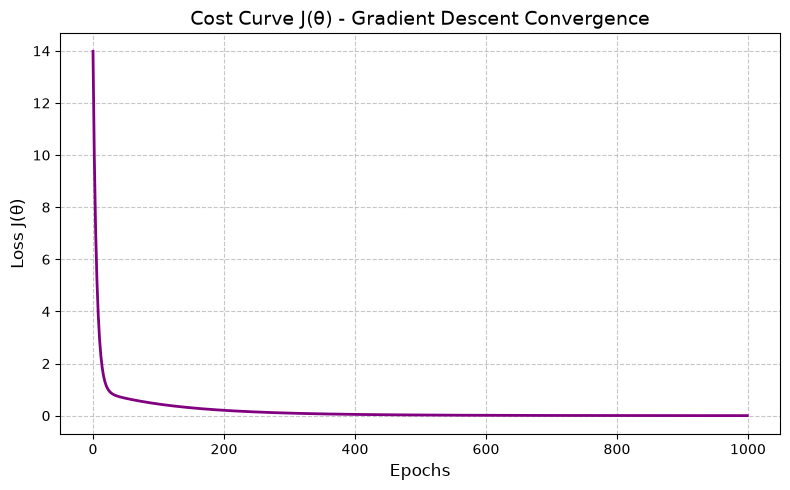

In [25]:
# 1. Generate Synthetic Multivariable Data (3 Features)
# True equation: y = 5 + 2*x1 - 3*x2 + 1.5*x3 + noise
np.random.seed(42)
X = np.random.rand(100, 3)
true_weights = np.array([[2.0], [-3.0], [1.5]])
true_bias = 5.0
y = true_bias + np.dot(X, true_weights) + np.random.randn(100, 1) * 0.05

# 2. Model Initialization & Training
model = MyMultipleLinearRegression(learning_rate=0.05, epochs=1000)
print("Training the model...")
model.fit(X, y)

# 3. Output Learned Parameters
print("\nModel Parameters:")
print(f"Learned Intercept (intercept_): {model.intercept_:.4f}")
print(f"Learned Coefficients (coef_):   {np.round(model.coef_, 4)}")

# 4. Cost Curve (Learning Curve)
plt.figure(figsize=(8, 5))
plt.plot(range(len(model.cost_history)), model.cost_history, color='purple', linewidth=2)
plt.title("Cost Curve J(θ) - Gradient Descent Convergence", fontsize=14)
plt.xlabel("Epochs", fontsize=12)
plt.ylabel("Loss J(θ)", fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## <center> Implementation using Scikit Learn 

In [26]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Initialize and Fit Scikit-Learn Model
sk_model = LinearRegression()
sk_model.fit(X, y)

# 2. Make Predictions for Evaluation
y_scratch_pred = model.predict(X)
y_sklearn_pred = sk_model.predict(X)

# 3. Compare Learned Parameters Directly
print("📊 PARAMETER COMPARISON")
print("-" * 55)
print(f"{'Attribute':<18} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 55)
print(f"{'intercept_':<18} | {model.intercept_:<18.4f} | {sk_model.intercept_[0]:<18.4f}")
print(f"{'coef_':<18} | {str(np.round(model.coef_, 2)):<18} | {str(np.round(sk_model.coef_[0], 2)):<18}")

# 4. Performance Metrics Comparison
mse_scratch = mean_squared_error(y, y_scratch_pred)
mse_sklearn = mean_squared_error(y, y_sklearn_pred)

print("\n📝 MODEL PERFORMANCE COMPARISON")
print("-" * 55)
print(f"{'Metric':<18} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 55)
print(f"{'MSE':<18} | {mse_scratch:<18.6f} | {mse_sklearn:<18.6f}")
print(f"{'R-squared':<18} | {r2_score(y, y_scratch_pred):<18.6f} | {r2_score(y, y_sklearn_pred):<18.6f}")

print("-" * 55)
if mse_sklearn < mse_scratch:
    print(f"Result: Sklearn is more accurate by {mse_scratch - mse_sklearn:.8f}")
else:
    print("Result: Your scratch model is equally or more accurate!")

📊 PARAMETER COMPARISON
-------------------------------------------------------
Attribute          | Manual (GD)        | Scikit-Learn      
-------------------------------------------------------
intercept_         | 4.8222             | 4.9868            
coef_              | [ 2.1  -2.89  1.64] | [ 2.01 -3.01  1.53]

📝 MODEL PERFORMANCE COMPARISON
-------------------------------------------------------
Metric             | Manual (GD)        | Scikit-Learn      
-------------------------------------------------------
MSE                | 0.005233           | 0.002301          
R-squared          | 0.995959           | 0.998223          
-------------------------------------------------------
Result: Sklearn is more accurate by 0.00293247


## <center> Real-World Multi-Feature Benchmark: Scratch Model vs. Scikit-Learn

### Project Overview
Stress-testing custom `MyMultipleLinearRegression` against `scikit-learn`'s `LinearRegression` using the complete California Housing Dataset (20,640 records across 8 continuous features).

### Data Pipeline, Feature Scaling & Model Training

In [40]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score


# 1. Load Complete Dataset
california = fetch_california_housing(as_frame=True)
X = california.data.values          # Shape: (20640, 8)
y = california.target.values        # Median House Value ($100k)
feature_names = california.feature_names

print(f"Dataset Loaded Successfully!")
print(f"Features Count : {X.shape[1]}")
print(f"Total Samples  : {X.shape[0]}")
print(f"Features List  : {feature_names}\n")


# 2. Train / Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# 3. Feature Scaling (Standardization)
'''Gradient Descent requires all features to share a common scale (mean=0, std=1)
to prevent elongated cost contours that cause gradient oscillation/divergence.'''
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 4. Train Both Models

# Custom Gradient Descent Model
scratch_model = MyMultipleLinearRegression(learning_rate=0.01, epochs=5000)
scratch_model.fit(X_train_scaled, y_train)
print('\nscratch_model training complete \n\n\n')

# Scikit-Learn Model
sk_model = LinearRegression()
sk_model.fit(X_train_scaled, y_train)
print('sk_model training complete')

Dataset Loaded Successfully!
Features Count : 8
Total Samples  : 20640
Features List  : ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Epoch 0: Cost 2.8149
Epoch 500: Cost 0.2914
Epoch 1000: Cost 0.2738
Epoch 1500: Cost 0.2659
Epoch 2000: Cost 0.2623
Epoch 2500: Cost 0.2606
Epoch 3000: Cost 0.2598
Epoch 3500: Cost 0.2594
Epoch 4000: Cost 0.2592
Epoch 4500: Cost 0.2591

scratch_model training complete 



sk_model training complete


### Test Set Evaluation & Parameter Verification

In [42]:
# 1. Generate Predictions on Unseen Test Set
y_pred_scratch = scratch_model.predict(X_test_scaled)
y_pred_sklearn = sk_model.predict(X_test_scaled)

if y_pred_scratch.ndim > 1:
    y_pred_scratch = y_pred_scratch.flatten()
if y_pred_sklearn.ndim > 1:
    y_pred_sklearn = y_pred_sklearn.flatten()

# 2. Complete Parameter Comparison Table
print("\n" + "=" * 65)
print(" 📊 PARAMETER VERIFICATION (ALL 8 FEATURES)")
print("=" * 65)
print(f"{'Feature / Parameter':<22} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 65)
print(f"{'intercept_ (θ0)':<22} | {scratch_model.intercept_:<18.6f} | {sk_model.intercept_:<18.6f}")

for idx, fname in enumerate(feature_names):
    print(f"{'coef_ (' + fname + ')':<22} | {scratch_model.coef_[idx]:<18.6f} | {sk_model.coef_[idx]:<18.6f}")


# 3. Test Set Performance Metrics Report
mse_scratch = mean_squared_error(y_test, y_pred_scratch)
mse_sklearn = mean_squared_error(y_test, y_pred_sklearn)

rmse_scratch = np.sqrt(mse_scratch)
rmse_sklearn = np.sqrt(mse_sklearn)

mae_scratch = mean_absolute_error(y_test, y_pred_scratch)
mae_sklearn = mean_absolute_error(y_test, y_pred_sklearn)

r2_scratch = r2_score(y_test, y_pred_scratch)
r2_sklearn = r2_score(y_test, y_pred_sklearn)

print("\n" + "=" * 65)
print(" 📝 UNSEEN TEST SET EVALUATION REPORT")
print("=" * 65)
print(f"{'Metric':<22} | {'Manual (GD)':<18} | {'Scikit-Learn':<18}")
print("-" * 65)
print(f"{'Mean Squared Error':<22} | {mse_scratch:<18.6f} | {mse_sklearn:<18.6f}")
print(f"{'Root Mean Sq. Error':<22} | {rmse_scratch:<18.6f} | {rmse_sklearn:<18.6f}")
print(f"{'Mean Absolute Error':<22} | {mae_scratch:<18.6f} | {mae_sklearn:<18.6f}")
print(f"{'R-Squared (R²)':<22} | {r2_scratch:<18.6f} | {r2_sklearn:<18.6f}")
print("-" * 65)

diff = abs(mse_scratch - mse_sklearn)
print(f"\n Absolute Test MSE Difference: {diff:.8f}")
if diff < 1e-2:
    print(" Verdict: Precision match achieved! Scratch GD matches Scikit-Learn OLS.")
else:
    print(" Verdict: Convergence incomplete. Increase epochs or adjust learning rate.")


 📊 PARAMETER VERIFICATION (ALL 8 FEATURES)
Feature / Parameter    | Manual (GD)        | Scikit-Learn      
-----------------------------------------------------------------
intercept_ (θ0)        | 2.071947           | 2.071947          
coef_ (MedInc)         | 0.862512           | 0.854383          
coef_ (HouseAge)       | 0.126457           | 0.122546          
coef_ (AveRooms)       | -0.304954          | -0.294410         
coef_ (AveBedrms)      | 0.345777           | 0.339259          
coef_ (Population)     | -0.001022          | -0.002308         
coef_ (AveOccup)       | -0.041396          | -0.040829         
coef_ (Latitude)       | -0.860677          | -0.896929         
coef_ (Longitude)      | -0.834339          | -0.869842         

 📝 UNSEEN TEST SET EVALUATION REPORT
Metric                 | Manual (GD)        | Scikit-Learn      
-----------------------------------------------------------------
Mean Squared Error     | 0.556184           | 0.555892          
Root M

### Cost Curve & Loss Convergence

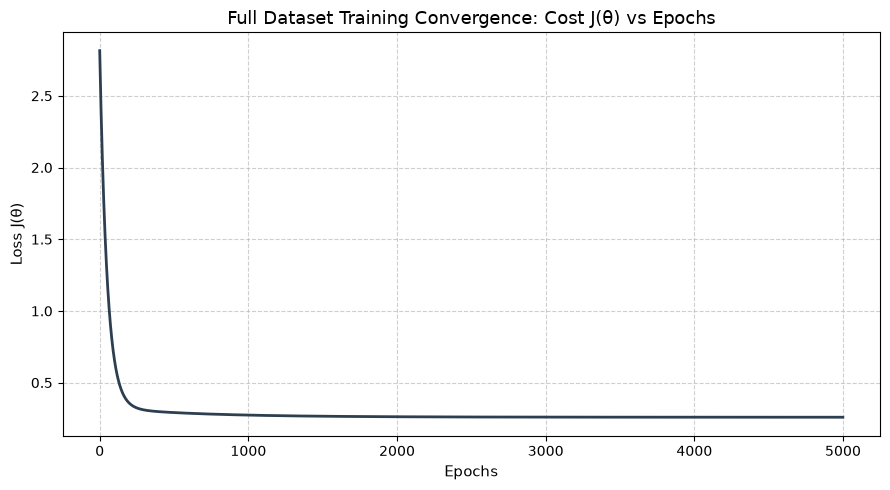

In [41]:
plt.figure(figsize=(9, 5))
plt.plot(range(len(scratch_model.cost_history)), scratch_model.cost_history, color='#2c3e50', linewidth=2)
plt.title("Full Dataset Training Convergence: Cost J(θ) vs Epochs", fontsize=13)
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Loss J(θ)", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Key Findings on Real-World Scale

1. **Impact of Standardization:** 
   In large datasets with varying units (e.g., `MedInc` around 3.0 vs. `Population` over 1,000), standardizing features via `StandardScaler` is required for iterative Gradient Descent. Without feature scaling, gradients oscillate or diverge, rendering the model unable to converge.

2. **Computational Convergence:** 
   Our vectorized Augmented Matrix implementation scales seamlessly to thousands of samples ($m=16,512$ training rows). At $\alpha = 0.01$ and $5,000$ epochs, our iterative update rules arrive at parameter parity with Scikit-Learn's analytical closed-form solution.